# IndustReal: Transferring Contact-Rich Assembly Tasks from Simulation to 
# Reality
   
   Abstract: Robotic assembly is a longstanding challenge, requiring 
   contact-rich interaction and high precision and accuracy. Many application 
   also require adaptivity to diverse parts, poses, and environmnets, as well
   as low cycle times. In other areas of robotics, simulation is a powerful 
   tool to develop algorithms, generate data ... IndustReal, a set of 
   algorithms, systems, and tools that solve assembly tasks in simulation with
   RL and successfully achieve policy transfer to the real world... 

   we propose... 
   1. Simulation-aware policy updates
   2. Signed-distance-field rewards
   3. Sampling-based curricula for robotic RL agents 


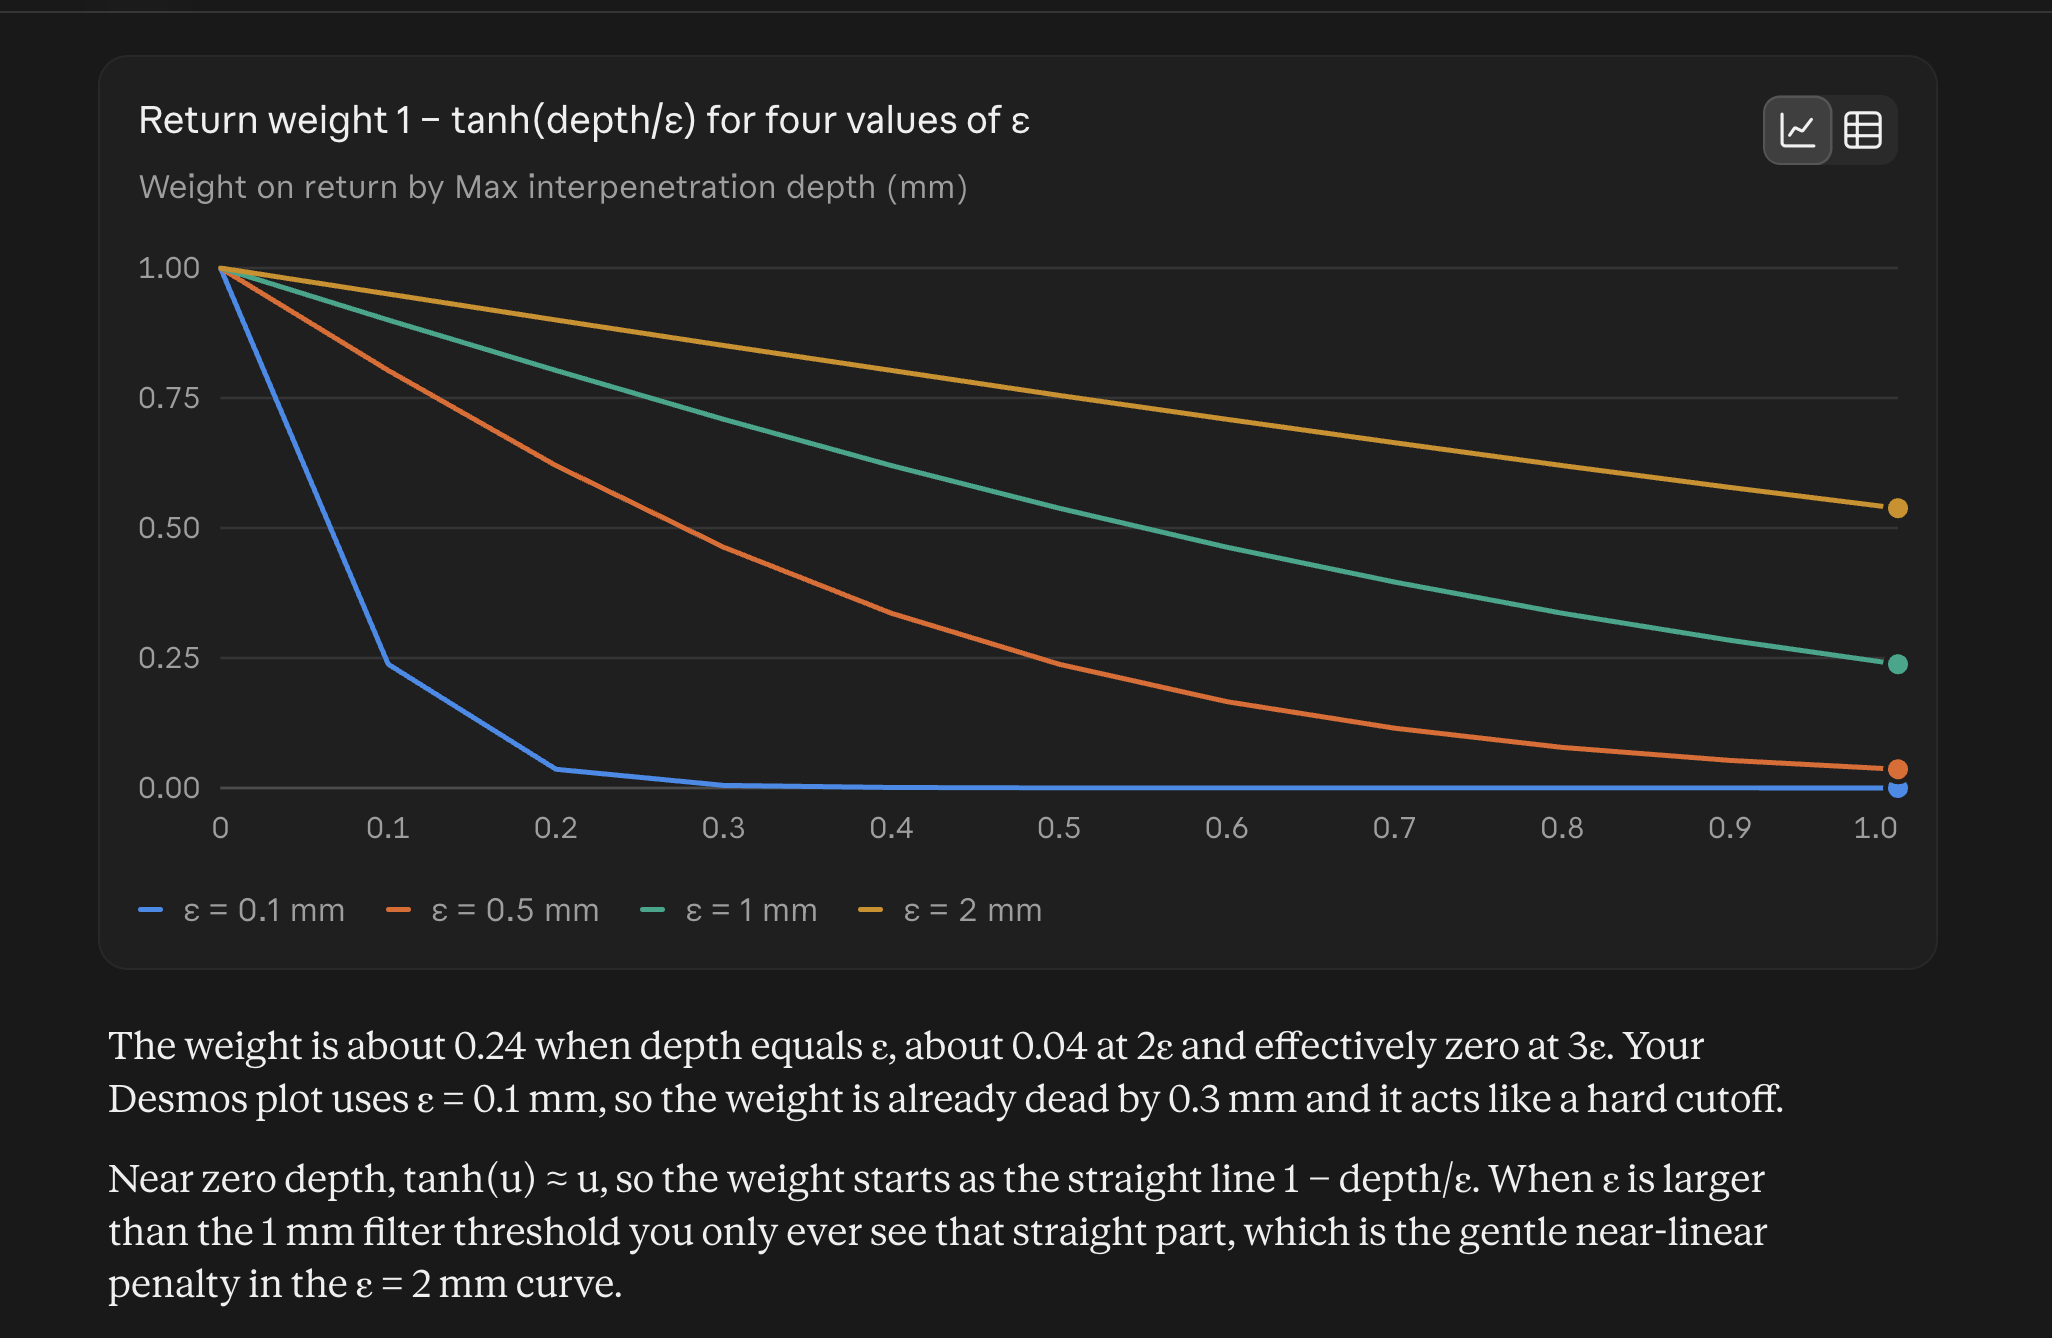

-- The weight is about 0.24 when depth equals $\epsilon$, about 0.04 when
   $2\epsilon$ and effectively zero at $3\epsilon$. ... 

   Near zero depth, `tanh(u) \approx u`, so the weight starts as the straight 
   line `1 - depth/eps` ... When `eps` is larger than the 1 mm filter
   threshold ... only see the strraight part ....

   So `\epsilon` is a tuning knob for strictness: small `\eps` punishes any
   penetratioin hard and large `\eps` forgives it.... 

-- Simulation-aware policy update (`SAPU`) handles the fact that simulators
   sometimes let parts pass through each other, which an RL agent will exploit
   to get reward. Each episode it measures how deep the plug penetrated the 
   socket, then it throws away the return above 1mm and scales it down



-- .. "return" is the total reward the agent collected over one episode, and 
   the 1mm is how deep the plug sank into the socket's solid body in simulation
   ... If that depth is more than 1mm theepisode is treated as physicall fake
   , so its return is not sued to update the policy at all... If the depth is
   under 1mm the return is multiplied by `1 - tanh (depth \ eps)`


-- ... "return" is a standard RL term from Suttona nd Barto, usually written G.
   It means the sum of rewards over an episode, often with a discount factor 
   that shrinks later rewards. "Reward" is the signal at one timestep, while
   "return" is the total the agent actually tries to maximise. ... 




-- "Many applications" means real factory assembly jobs, and the introduction
   names the main case as high-mix low-volume production when a line builds
   many product types in small batches. 
   
-- "Adaptivity to diverse parts, poses, and environments" means the robot must
   handle different par shapes, ... parts that start in different positions and
   different workcell setup without an engineer rebuilding fixtures or 
   reprogramming paths each time. 

-- "Low cycle times" ... standard manufaturing term for the time to finish one
   assembly operation. The sentence ... says a useful assembly robot must be
   flexible and fast as well as precise, which is why assembly is hard... 

---

TDL: 
    Simulation-aware policy update (SAPU) handles the fact that simulators sometimes let parts pass through each other, which an RL agent will explo

    .....

    https://claude.ai/chat/2bb4319c-15b3-4aac-9fa1-0e9da1c11987

   Simulation-aware policy update (SAPU) handles the fact that simulators 
   sometimes let parts through each other, which an RL agent will exploit to
   get reward. Each episode it measures how deep the plug penetrated the socket
   , then it throws away the `return` above 1 mm and scales it down below that
   ...

   The SDF reward answers "how far is the plug from its goal pose" for any
   shape, because keypoint rewards fail on 


   The SDF reward answers "how far is the plug from its goal pose" for any 
   shape, because keypoint rewards fail on parts like rectangular pegs or
   symmetric gears. It stores a distance field around the plug 

1. Simulation-aware policy update (SAPU) handles the fact that simulators 
   sometimes let parts through each other, which an RL agent will exploit to
   get reward. Each episode it measures how deep the plug penetrated the socket
   , then it throws away the `return` above 1 mm and scales it down below that
   
2. The SDF reward answers "how far is the plug from its goal pose" for 
   any shape, becase keypoint rewards fail on parts like rectangular pegs or
   symmetric gears. It stores a distance field around the plug at its target
   pose, then at each step it reads that field at each step it reads that
   field at 1000 pints n the current plug surface and use
   the RMS distance ss the reward signal ... 

3. The sampling-based curriculum (SBC) fixes a failure where the agent starts
   with the peg partly inserted and never learns to handle a peg that starts
   above the hole. It samples the start height uniformly between a lower bound 
   and a fixed upper bound from the first stage, and it raises the lower bound
   only when success passes 80% 

4. 




-- PLAI is a small change to how the policy's actins are turned into robot
   targets, and it is used only at deployment time. The policy outputs a small
   move (an incremental target) at each step. Normally that move is added to
   where the robot actually is now. PLAI instead adds it to the last target it
   sent. 

   The matters because of friction and gravity on the real robot. Say the 
   policy asks to move 1 mm down but friction stops the arm 0.5 mm short. In
   the normal scheme the next target starts again from that short position,
   so the arm can settle a few millimeters off the gooal and stay there 
   (steady-state error) ... With PLAI the target keeps running ahead of the arm
   until the arm catches up

   So the target is the start pose plus the sum of all plus actions, which is
   where the "integrator" in the name comes from. It acts like the I term in a
   PID controller. It is still closed-loop because the policy keeps reacting to
   fresh observations at each step ... authors say it takes 1-2 lines of code. 

   The risk if windup. If the plug is pressed against a surface, the summed
   target can keep growing and push too hard. Their fix is Leaky PLAI, which
   caps how far the accumulated target can grow ...

   On results, the plain method was off by up to 6.9 cm in simulation once
   they added friction. PLAI stayed near 2mm under every condition they tested,
   in simulation and on the real arm ...




-- ... the target at time T is the start pose plus the sum of every action
   so far, and a running sum is the discrete version of an integral. The 
   policy's actions get bigger when the error is bigger, so the target is
   in effect summing up the error over time. This is the same job the I term
   does in a PID controller, which is why the authors say PLAI is closely 
   related to a policy combined with PID control. So the name comes from the
   maths and not just from how the graph looks, because any error that persists
   keeps adding to the target until the arm closes the gap...





-- PLAI is a small change to how the policy's actions are turned into robot
   targets, and it is used only at deployment time. The policy outputs a small 
   move (an incremental target) at each step ... Normally that move is added 
   Normally that move is added to where the robot actually is now. PLAI
   instead adds it to the last target it sent ... 





-- .. In robotic assembly, ... a CHAMFER INSERTION METRIC measures how well a
   robot aligns and insert a part into a beveled opening without jamming or
   colliding ... 

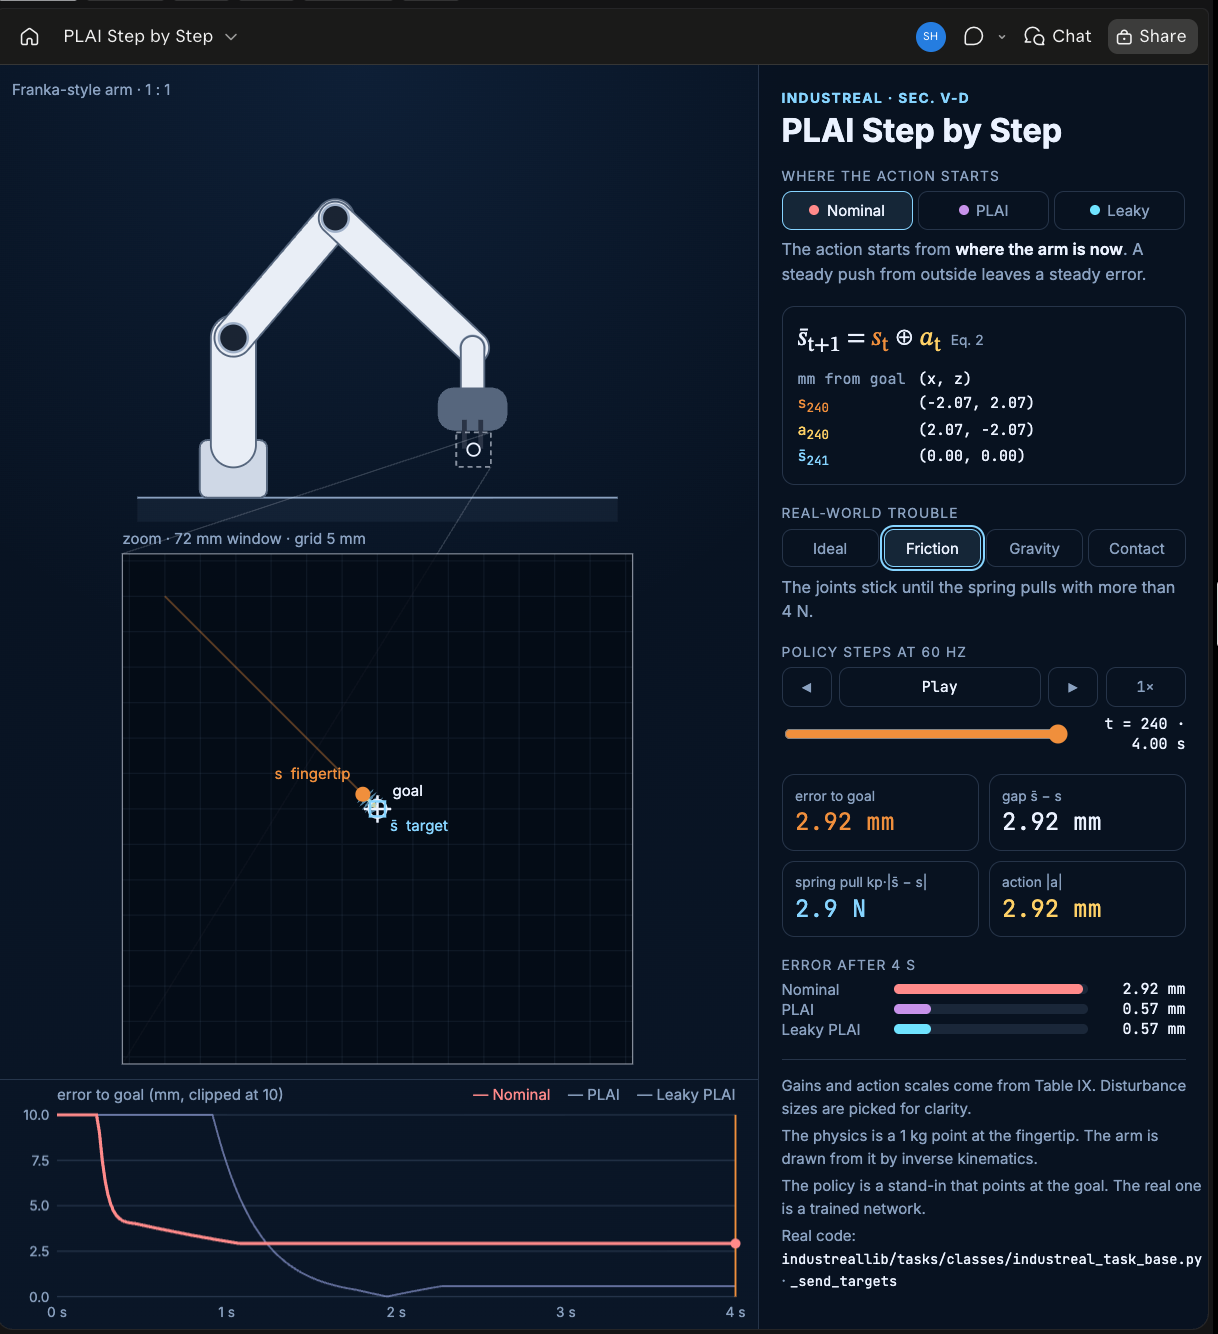

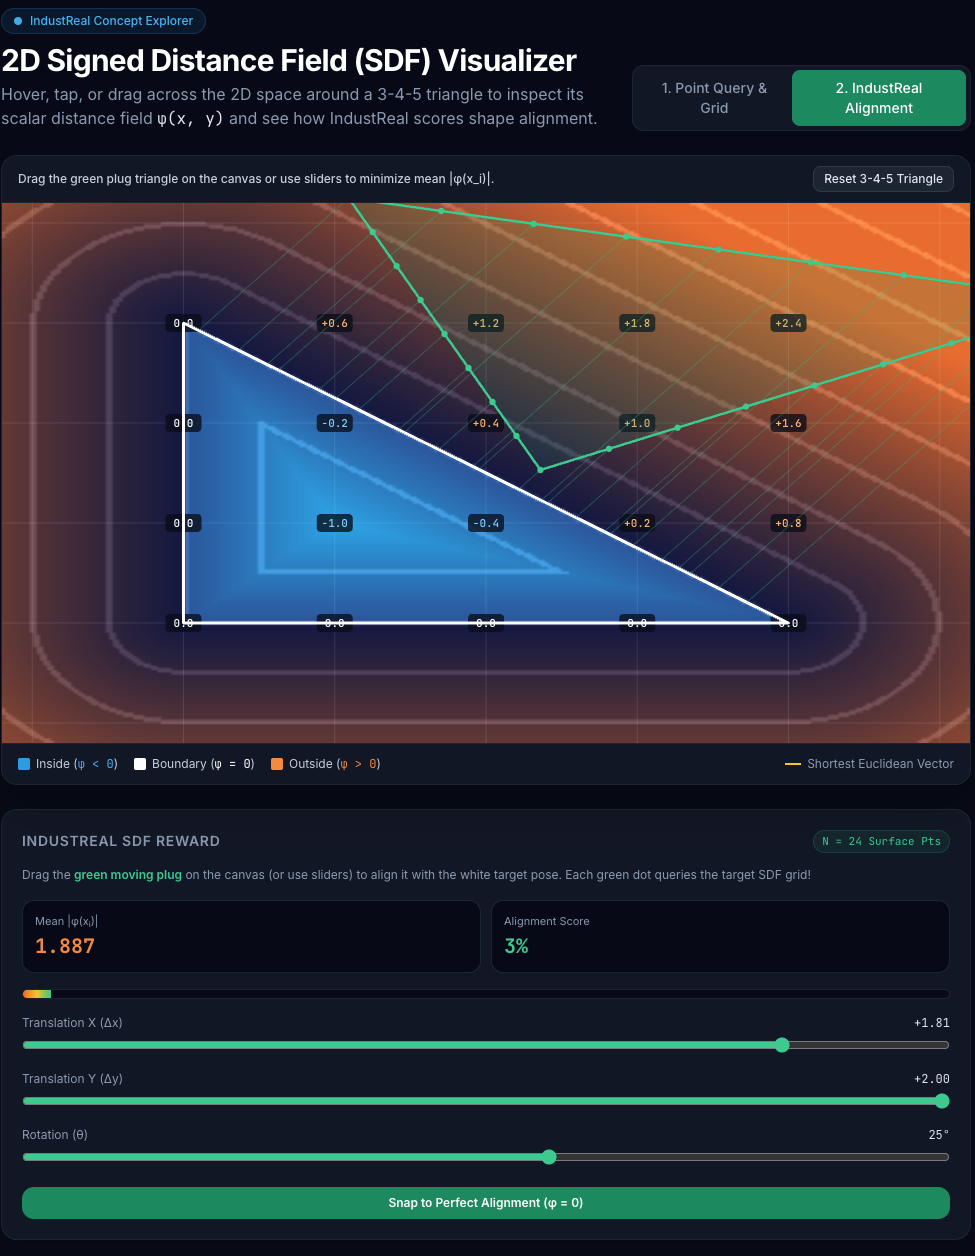

-- 


-- A keypoint reward marks a few fixed points on the object and the same
   points on a copy of it at the goal pose, then it rewards the agent
   for making the distance between each matching pair small ... People use it
   because one distance number covers both position and rotation error, so there 
   is no need to tune a weight between the two ...

   It fails when the points do not descrive the shape well... like symmetry
   being punished... for poses which are in fact correct. 
   

-- `return` is the total reward the agent collected over one episode ... and
   2mm is how deep the plug sank into the socket's solid body in sim